In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/spscientist/students-performance-in-exams/StudentsPerformance.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv(r'/kaggle/input/datasets/spscientist/students-performance-in-exams/StudentsPerformance.csv')

In [4]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [5]:
df.shape

(1000, 8)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [7]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [8]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='math score', ylabel='Count'>

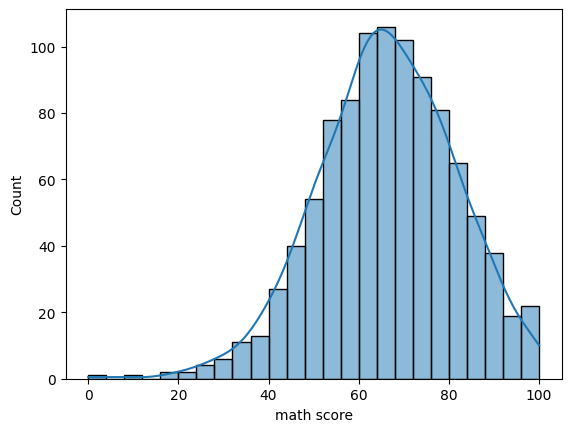

In [13]:
sns.histplot(x=df['math score'],kde=True) #left skewed

<Axes: xlabel='writing score', ylabel='math score'>

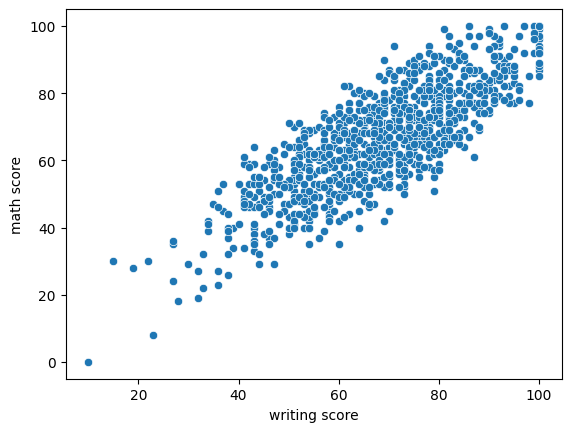

In [22]:
sns.scatterplot(x='writing score', y='math score', data=df)

<Axes: xlabel='reading score', ylabel='math score'>

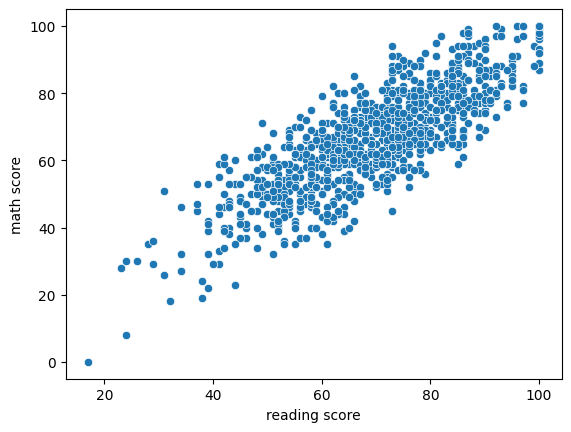

In [24]:
sns.scatterplot(x='reading score', y='math score', data=df)

<Axes: >

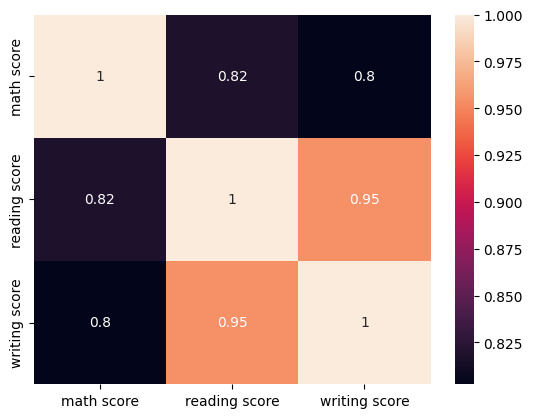

In [42]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

<Axes: xlabel='gender', ylabel='math score'>

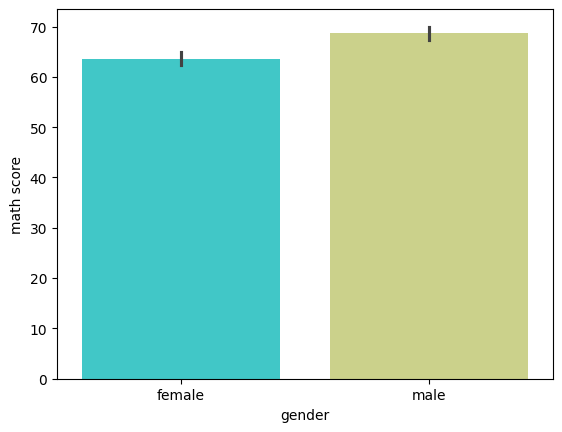

In [26]:
sns.barplot(x="gender",y="math score",data=df,palette="rainbow")

<Axes: xlabel='race/ethnicity', ylabel='math score'>

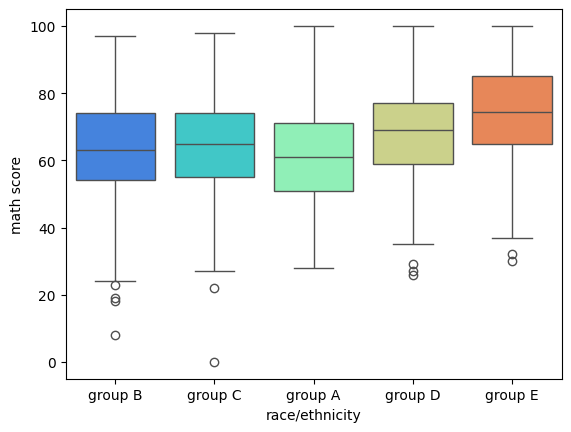

In [29]:
sns.boxplot(x="race/ethnicity",y="math score",data=df,palette="rainbow")

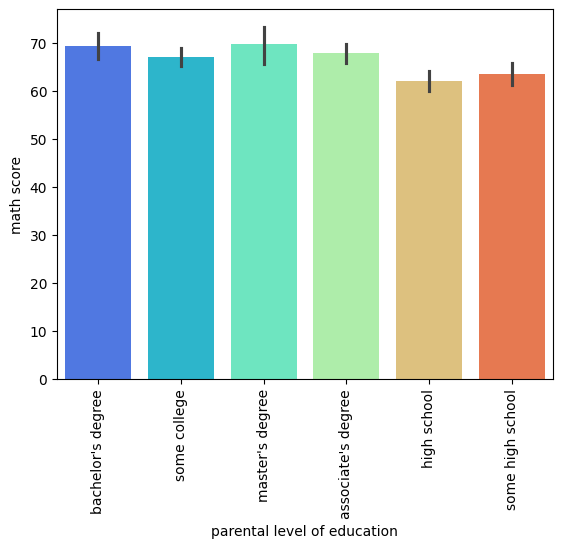

In [33]:
sns.barplot(x="parental level of education",y="math score",data=df,palette="rainbow") #highest education level of the student’s parent(s)
plt.xticks(rotation=90)
plt.show()

<Axes: xlabel='lunch', ylabel='math score'>

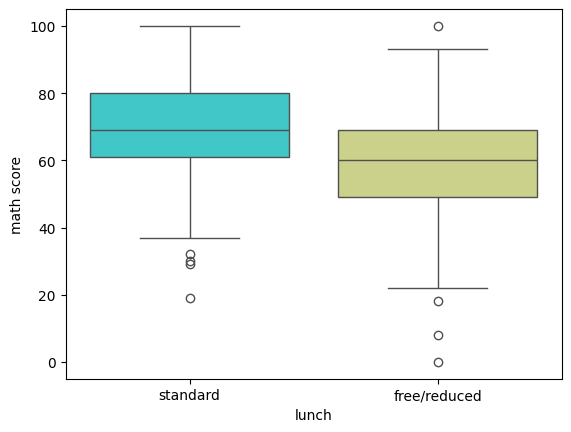

In [35]:
sns.boxplot(x="lunch",y="math score",data=df,palette="rainbow")

<Axes: xlabel='test preparation course', ylabel='math score'>

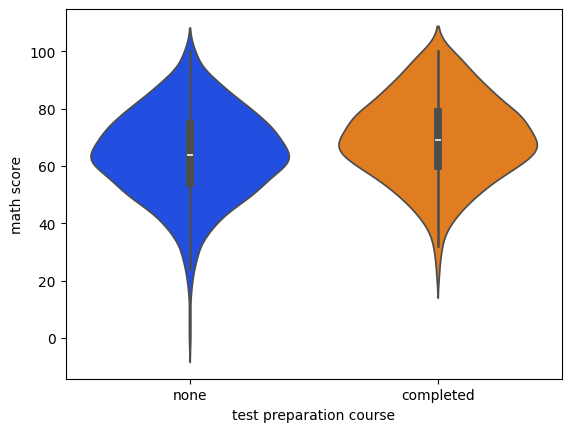

In [38]:
sns.violinplot(x="test preparation course",y="math score",data=df,palette="bright")

In [56]:
X = df.drop(columns=['math score'])
y = df['math score']

In [57]:
X

,gender,race/ethnicity,parental level of education,lunch,test preparation course,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,74
1,female,group C,some college,standard,completed,90,88
2,female,group B,master's degree,standard,none,95,93
3,male,group A,associate's degree,free/reduced,none,57,44
4,male,group C,some college,standard,none,78,75
...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,99,95
996,male,group C,high school,free/reduced,none,55,55
997,female,group C,high school,free/reduced,completed,71,65
998,female,group D,some college,standard,completed,78,77


In [58]:
y

0      72
1      69
2      90
3      47
4      76
       ..
995    88
996    62
997    59
998    68
999    77
Name: math score, Length: 1000, dtype: int64

In [59]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

In [60]:
X_one_encode = pd.get_dummies(X,columns=['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course'],drop_first=True)
X_one_encode

,reading score,writing score,gender_male,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_standard,test preparation course_none
0,72,74,False,True,False,False,False,True,False,False,False,False,True,True
1,90,88,False,False,True,False,False,False,False,False,True,False,True,False
2,95,93,False,True,False,False,False,False,False,True,False,False,True,True
3,57,44,True,False,False,False,False,False,False,False,False,False,False,True
4,78,75,True,False,True,False,False,False,False,False,True,False,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,99,95,False,False,False,False,True,False,False,True,False,False,True,False
996,55,55,True,False,True,False,False,False,True,False,False,False,False,True
997,71,65,False,False,True,False,False,False,True,False,False,False,False,False
998,78,77,False,False,False,True,False,False,False,False,True,False,True,False


In [62]:
X_one_encode = X_one_encode.astype(int)
X_one_encode

,reading score,writing score,gender_male,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_standard,test preparation course_none
0,72,74,0,1,0,0,0,1,0,0,0,0,1,1
1,90,88,0,0,1,0,0,0,0,0,1,0,1,0
2,95,93,0,1,0,0,0,0,0,1,0,0,1,1
3,57,44,1,0,0,0,0,0,0,0,0,0,0,1
4,78,75,1,0,1,0,0,0,0,0,1,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,99,95,0,0,0,0,1,0,0,1,0,0,1,0
996,55,55,1,0,1,0,0,0,1,0,0,0,0,1
997,71,65,0,0,1,0,0,0,1,0,0,0,0,0
998,78,77,0,0,0,1,0,0,0,0,1,0,1,0


In [64]:
from sklearn.preprocessing import LabelEncoder
columns = ['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course']
X_label = X.copy()
label_Encoder = {}
for col in columns:
    le = LabelEncoder()
    X_label[col]=le.fit_transform(X_label[col].astype(str))
    label_Encoder[col]=le

In [65]:
X_label

,gender,race/ethnicity,parental level of education,lunch,test preparation course,reading score,writing score
0,0,1,1,1,1,72,74
1,0,2,4,1,0,90,88
2,0,1,3,1,1,95,93
3,1,0,0,0,1,57,44
4,1,2,4,1,1,78,75
...,...,...,...,...,...,...,...
995,0,4,3,1,0,99,95
996,1,2,2,0,1,55,55
997,0,2,2,0,0,71,65
998,0,3,4,1,0,78,77


In [69]:
from sklearn.preprocessing import StandardScaler
nums_columns = ['reading score','writing score']
scaler = StandardScaler()
X_one_encode[nums_columns]=scaler.fit_transform(X_one_encode[nums_columns])
X_one_encode

,reading score,writing score,gender_male,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_standard,test preparation course_none
0,0.193999,0.391492,0,1,0,0,0,1,0,0,0,0,1,1
1,1.427476,1.313269,0,0,1,0,0,0,0,0,1,0,1,0
2,1.770109,1.642475,0,1,0,0,0,0,0,1,0,0,1,1
3,-0.833899,-1.583744,1,0,0,0,0,0,0,0,0,0,0,1
4,0.605158,0.457333,1,0,1,0,0,0,0,0,1,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,2.044215,1.774157,0,0,0,0,1,0,0,1,0,0,1,0
996,-0.970952,-0.859491,1,0,1,0,0,0,1,0,0,0,0,1
997,0.125472,-0.201079,0,0,1,0,0,0,1,0,0,0,0,0
998,0.605158,0.589015,0,0,0,1,0,0,0,0,1,0,1,0


In [71]:
X_label[['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course','reading score',
       'writing score']]=scaler.fit_transform(X_label[['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course','reading score',
       'writing score']])
X_label

,gender,race/ethnicity,parental level of education,lunch,test preparation course,reading score,writing score
0,-0.964625,-1.015044,-0.812640,0.741881,0.746748,0.193999,0.391492
1,-0.964625,-0.150441,0.827953,0.741881,-1.339140,1.427476,1.313269
2,-0.964625,-1.015044,0.281088,0.741881,0.746748,1.770109,1.642475
3,1.036672,-1.879647,-1.359505,-1.347925,0.746748,-0.833899,-1.583744
4,1.036672,-0.150441,0.827953,0.741881,0.746748,0.605158,0.457333
...,...,...,...,...,...,...,...
995,-0.964625,1.578765,0.281088,0.741881,-1.339140,2.044215,1.774157
996,1.036672,-0.150441,-0.265776,-1.347925,0.746748,-0.970952,-0.859491
997,-0.964625,-0.150441,-0.265776,-1.347925,-1.339140,0.125472,-0.201079
998,-0.964625,0.714162,0.827953,0.741881,-1.339140,0.605158,0.589015


In [72]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [73]:
X_train,X_test,y_train,y_test = train_test_split(X_one_encode,y,test_size = 0.25,random_state=42)

In [74]:
model = LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

In [75]:
y_pred = model.predict(X_test)
y_pred

array([76.41555568, 58.8353565 , 76.90737039, 76.76003245, 87.45400743,
       79.07262897, 64.71942164, 52.86064898, 74.288464  , 48.97857704,
       53.45912628, 36.27115204, 67.91083798, 52.03636482, 86.69229605,
       70.47398945, 51.69157205, 46.73705123, 48.53085756, 52.68172401,
       73.81806167, 39.01200589, 57.37534859, 36.16151043, 78.15769064,
       81.79603924, 75.44054097, 46.03943655, 31.56295458, 49.69402734,
       65.69195967, 70.37535533, 60.37756226, 83.46157173, 84.10929911,
       45.82528512, 76.10113115, 69.96897845, 65.75328769,  3.49328797,
       78.70426007, 67.11699063, 68.05666076, 60.67305712, 79.63578117,
       67.54767442, 72.1481181 , 24.57717025, 85.88035604, 70.66633426,
       75.27052326, 66.72281985, 81.17582852, 45.55076823, 65.96434136,
       67.08205581, 86.11272348, 58.72803086, 82.10967442, 81.804249  ,
       47.75749588, 72.12947971, 70.68399799, 55.72065317, 86.4196875 ,
       64.07428971, 59.27481523, 55.85855015, 57.20254601, 82.07

In [76]:
y_test

521    91
737    53
740    80
660    74
411    84
       ..
109    70
430    64
77     80
84     42
286    97
Name: math score, Length: 250, dtype: int64

In [77]:
r2 = r2_score(y_test,y_pred)
r2

0.8778243107659014

In [78]:
n = X_test.shape[0]
p = X_test.shape[1]
adjusted_r2 = 1 - ((1 - r2) * (n - 1)) / (n - p - 1)
print("Adjusted R² Score:", adjusted_r2)

Adjusted R² Score: 0.8705457590668487


In [80]:
X_train, X_test, y_train, y_test = train_test_split(X_label, y, test_size=0.25, random_state=42)

In [81]:
model2 = LinearRegression()
model2.fit(X_train,y_train)

LinearRegression()

In [82]:
y_pred = model2.predict(X_test)
y_pred

array([77.15116548, 57.27107699, 79.25053081, 77.1078633 , 84.74241383,
       79.90553255, 64.71245911, 52.49689093, 74.72025917, 49.94920206,
       50.60915724, 33.86164348, 66.56038786, 53.4775363 , 87.77638699,
       72.07649009, 53.69701588, 49.26852358, 50.59372539, 54.26392892,
       76.52037194, 40.86322482, 58.36266221, 37.27309382, 79.8061978 ,
       82.93087654, 78.22787657, 47.66550332, 30.29926693, 50.61010335,
       64.78731989, 71.2741535 , 60.77752007, 79.72363837, 81.00725996,
       44.34599284, 77.70221954, 71.08286841, 68.63275318,  5.27220481,
       79.57125975, 67.05818911, 70.28332364, 58.03055104, 81.840526  ,
       63.25563471, 72.85777893, 25.04795571, 88.23434771, 68.83895469,
       74.87046726, 68.38870048, 81.95886388, 44.59421212, 66.64299743,
       68.22818355, 87.80183731, 59.66593236, 82.08869407, 79.97127646,
       46.30949579, 72.74286515, 71.11610983, 53.85523501, 89.71501032,
       65.27814103, 60.45140549, 55.92808017, 57.81944374, 83.93

In [83]:
y_test

521    91
737    53
740    80
660    74
411    84
       ..
109    70
430    64
77     80
84     42
286    97
Name: math score, Length: 250, dtype: int64

In [84]:
r2 = r2_score(y_test,y_pred)
r2

0.8795296105895842

In [85]:
n = X_test.shape[0]
p = X_test.shape[1]
adjusted_r2 = 1 - ((1 - r2) * (n - 1)) / (n - p - 1)
print("Adjusted R² Score:", adjusted_r2)

Adjusted R² Score: 0.8760449299041589


# Here both model(on the basis of One_Hot_Encodeing) and model2(on the basis of Normal Labelling) have approximately equal accuracy